# Temperature Prediction using MLP Regressor

## Indravani Weather Intelligence
### Climate R&D Internship

**Model:** MLP Regressor

**Target Variable:** Temperature (`temp`)

**Dataset:** Historical Weather Data (Approx. 300,000 Records)

**Objective:**
Develop a machine learning model to predict future temperature values using historical temperature observations.

In [1]:
# ==========================================
# Temperature Prediction using MLP Regressor
# Import Required Libraries
# ==========================================

# Data Handling
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Model Saving
import joblib

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
# ==========================================
# Step 1: Upload Dataset
# ==========================================

from google.colab import files

uploaded = files.upload()

Saving Weather3past.csv to Weather3past.csv


In [4]:
# ==========================================
# Step 2: Load the Dataset
# ==========================================

df = pd.read_csv("Weather3past.csv")

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [5]:
# ==========================================
# Step 3: Explore the Dataset
# ==========================================

print("Shape of Dataset:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nFirst 5 Rows:")
display(df.head())

Shape of Dataset: (297828, 4)

Column Names:
Index(['_id', 'datetime', 'temp', 'rh'], dtype='object')

First 5 Rows:


,_id,datetime,temp,rh
0,65ec7952a00f951ad6604b14,2017-12-31 18:45:00,19.06,68.14
1,65ec7952a00f951ad6604b22,2017-12-31 22:15:00,17.55,75.70
2,65ec7952a00f951ad6604b2f,2018-01-01 01:30:00,16.60,75.43
3,65ec7952a00f951ad6604b54,2018-01-01 10:45:00,25.78,48.12
4,65ec7952a00f951ad6604b2c,2018-01-01 00:45:00,16.77,74.52


In [6]:
# ==========================================
# Step 4: Dataset Information
# ==========================================

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297828 entries, 0 to 297827
Data columns (total 4 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   _id       297828 non-null  object 
 1   datetime  297828 non-null  object 
 2   temp      297828 non-null  float64
 3   rh        297828 non-null  float64
dtypes: float64(2), object(2)
memory usage: 9.1+ MB


In [7]:
# ==========================================
# Step 5: Statistical Summary
# ==========================================

df.describe()

,temp,rh
count,297828.000000,297828.000000
mean,28.144489,70.512786
std,3.500817,15.913210
min,12.100000,13.100000
25%,26.010000,59.950000
50%,28.080000,72.560000
75%,30.400000,83.020000
max,40.800000,100.600000


In [8]:
# ==========================================
# Step 6: Data Preprocessing
# ==========================================

# Keep only required columns
df = df[['datetime', 'temp']]

# Convert datetime column to datetime format
df['datetime'] = pd.to_datetime(df['datetime'])

# Sort data chronologically
df = df.sort_values(by='datetime')

# Reset index
df.reset_index(drop=True, inplace=True)

print("Data preprocessing completed successfully!")

display(df.head())

Data preprocessing completed successfully!


,datetime,temp
0,2017-12-31 18:30:00,19.12
1,2017-12-31 18:45:00,19.06
2,2017-12-31 19:00:00,18.96
3,2017-12-31 19:15:00,18.97
4,2017-12-31 19:30:00,18.90


In [9]:
# ==========================================
# Step 7: Verify Chronological Order
# ==========================================

print("First 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

First 5 Records:


,datetime,temp
0,2017-12-31 18:30:00,19.12
1,2017-12-31 18:45:00,19.06
2,2017-12-31 19:00:00,18.96
3,2017-12-31 19:15:00,18.97
4,2017-12-31 19:30:00,18.90



Last 5 Records:


,datetime,temp
297823,2026-06-30 02:15:00,26.776905
297824,2026-06-30 02:30:00,26.913333
297825,2026-06-30 02:45:00,27.110000
297826,2026-06-30 03:00:00,27.341905
297827,2026-06-30 03:15:00,27.437500


In [12]:
# ==========================================
# Step 8: Create Lag Features
# ==========================================

NUM_LAGS = 10

for i in range(1, NUM_LAGS + 1):
    df[f'lag_{i}'] = df['temp'].shift(i)

# Remove rows containing NaN values created by shifting
df.dropna(inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

print("Lag Features Created Successfully!")

display(df.head())

Lag Features Created Successfully!


,datetime,temp,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10
0,2017-12-31 21:00:00,17.96,18.08,18.24,18.28,18.48,18.63,18.90,18.97,18.96,19.06,19.12
1,2017-12-31 21:15:00,17.82,17.96,18.08,18.24,18.28,18.48,18.63,18.90,18.97,18.96,19.06
2,2017-12-31 21:30:00,17.75,17.82,17.96,18.08,18.24,18.28,18.48,18.63,18.90,18.97,18.96
3,2017-12-31 21:45:00,17.71,17.75,17.82,17.96,18.08,18.24,18.28,18.48,18.63,18.90,18.97
4,2017-12-31 22:00:00,17.60,17.71,17.75,17.82,17.96,18.08,18.24,18.28,18.48,18.63,18.90


In [13]:
# ==========================================
# Step 9: Prepare Features and Target
# ==========================================

# Input Features
X = df.drop(columns=['datetime', 'temp'])

# Target Variable
y = df['temp']

print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Matrix Shape: (297818, 10)
Target Shape: (297818,)


In [14]:
# ==========================================
# Step 10: Train-Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    shuffle=False
)

print("Training Samples :", X_train.shape[0])
print("Testing Samples  :", X_test.shape[0])

Training Samples : 238254
Testing Samples  : 59564


In [15]:
# ==========================================
# Step 11: Feature Scaling
# ==========================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [16]:
# ==========================================
# Mount Google Drive
# ==========================================

from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

In [17]:
# ==========================================
# Step 12: Build MLP Regressor Model
# ==========================================

mlp_model = MLPRegressor(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    learning_rate='adaptive',
    max_iter=300,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    verbose=True
)

print("MLP Regressor Model Created Successfully!")

MLP Regressor Model Created Successfully!


In [18]:
# ==========================================
# Step 13: Train the MLP Regressor
# ==========================================

import time

# Record training start time
start_time = time.time()

# Train the model
mlp_model.fit(X_train, y_train)

# Record training end time
end_time = time.time()

training_time = end_time - start_time

print("\nModel Training Completed Successfully!")
print(f"Training Time: {training_time:.2f} seconds")

Iteration 1, loss = 25.38049234
Validation score: 0.992045
Iteration 2, loss = 0.03802274
Validation score: 0.994756
Iteration 3, loss = 0.03315855
Validation score: 0.994902
Iteration 4, loss = 0.03274552
Validation score: 0.994759
Iteration 5, loss = 0.03154297
Validation score: 0.992080
Iteration 6, loss = 0.03164309
Validation score: 0.994935
Iteration 7, loss = 0.03152890
Validation score: 0.988343
Iteration 8, loss = 0.03199064
Validation score: 0.995618
Iteration 9, loss = 0.03144236
Validation score: 0.993995
Iteration 10, loss = 0.03218496
Validation score: 0.993755
Iteration 11, loss = 0.03120735
Validation score: 0.994987
Iteration 12, loss = 0.03142252
Validation score: 0.995957
Iteration 13, loss = 0.03029814
Validation score: 0.995185
Iteration 14, loss = 0.03101451
Validation score: 0.994844
Iteration 15, loss = 0.03040168
Validation score: 0.995111
Iteration 16, loss = 0.03024523
Validation score: 0.995508
Iteration 17, loss = 0.03025330
Validation score: 0.996195
Itera

In [19]:
# ==========================================
# Step 14: Predict Temperature
# ==========================================

import time

# Prediction Start Time
start_time = time.time()

# Predict Temperature
y_pred = mlp_model.predict(X_test)

# Prediction End Time
end_time = time.time()

prediction_time = end_time - start_time

print("Prediction Completed Successfully!")
print(f"Prediction Time: {prediction_time:.4f} seconds")

Prediction Completed Successfully!
Prediction Time: 0.5195 seconds


In [20]:
# ==========================================
# Step 15: Model Evaluation
# ==========================================

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=" * 60)
print("        TEMPERATURE PREDICTION USING MLP REGRESSOR")
print("=" * 60)

print(f"Mean Absolute Error (MAE)      : {mae:.4f}")
print(f"Mean Squared Error (MSE)       : {mse:.4f}")
print(f"Root Mean Squared Error (RMSE) : {rmse:.4f}")
print(f"R² Score                       : {r2:.4f}")

print("\n" + "=" * 60)

print(f"Training Time   : {training_time:.2f} seconds")
print(f"Prediction Time : {prediction_time:.4f} seconds")

print("=" * 60)

        TEMPERATURE PREDICTION USING MLP REGRESSOR
Mean Absolute Error (MAE)      : 0.1472
Mean Squared Error (MSE)       : 0.0619
Root Mean Squared Error (RMSE) : 0.2488
R² Score                       : 0.9955

Training Time   : 91.77 seconds
Prediction Time : 0.5195 seconds


In [21]:
# ==========================================
# Step 16: Mean Absolute Percentage Error
# ==========================================

mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

Mean Absolute Percentage Error (MAPE): 0.50%


In [22]:
print(df.shape)


(297818, 12)


In [23]:
# ==========================================
# Step 17: Actual vs Predicted Values
# ==========================================

comparison = pd.DataFrame({
    'Actual Temperature': y_test.values,
    'Predicted Temperature': y_pred
})

comparison.head(20)

,Actual Temperature,Predicted Temperature
0,30.100000,30.099268
1,30.100000,30.067835
2,30.033333,30.073516
3,29.650000,29.992363
4,29.550000,29.501557
5,29.550000,29.403329
6,29.700000,29.490883
7,29.733333,29.677018
8,29.700000,29.762026
9,29.700000,29.699923


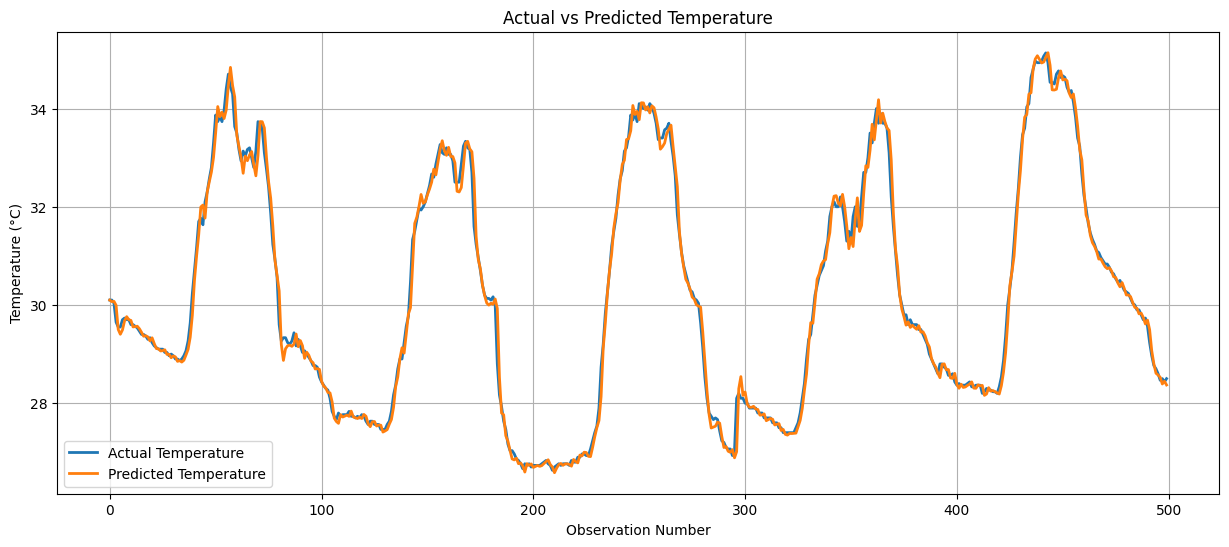

In [24]:
# ==========================================
# Step 18: Actual vs Predicted Graph
# ==========================================

plt.figure(figsize=(15,6))

plt.plot(
    y_test.values[:500],
    label='Actual Temperature',
    linewidth=2
)

plt.plot(
    y_pred[:500],
    label='Predicted Temperature',
    linewidth=2
)

plt.title("Actual vs Predicted Temperature")

plt.xlabel("Observation Number")

plt.ylabel("Temperature (°C)")

plt.legend()

plt.grid(True)

plt.show()

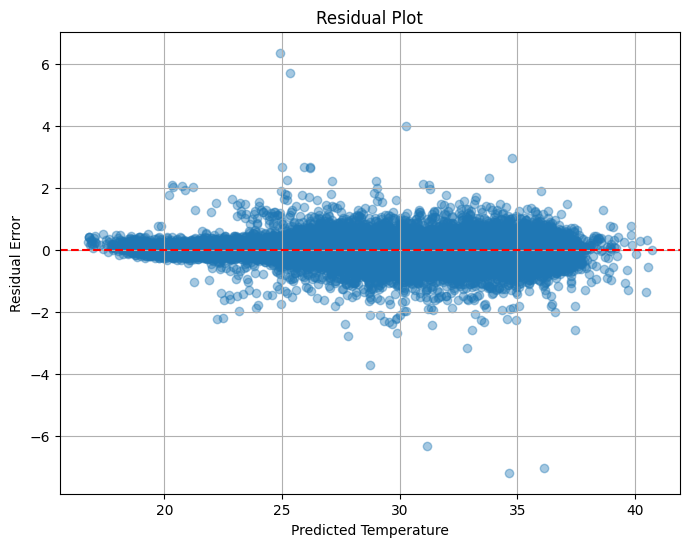

In [25]:
# ==========================================
# Step 19: Residual Plot
# ==========================================

residuals = y_test - y_pred

plt.figure(figsize=(8,6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.4
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.title("Residual Plot")

plt.xlabel("Predicted Temperature")

plt.ylabel("Residual Error")

plt.grid(True)

plt.show()

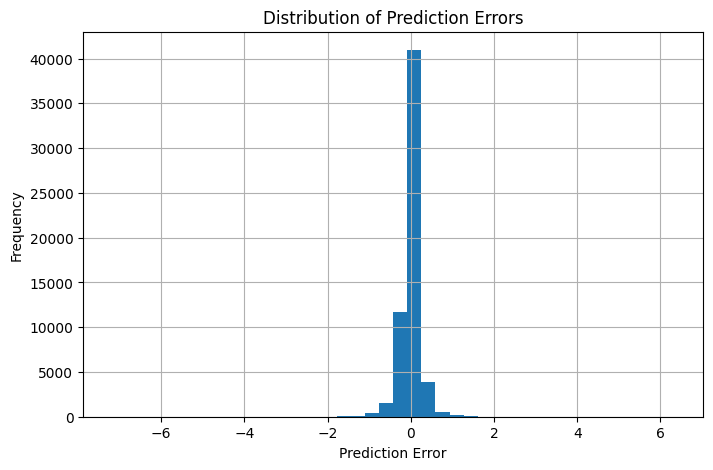

In [26]:
# ==========================================
# Step 20: Error Distribution
# ==========================================

plt.figure(figsize=(8,5))

plt.hist(
    residuals,
    bins=40
)

plt.title("Distribution of Prediction Errors")

plt.xlabel("Prediction Error")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

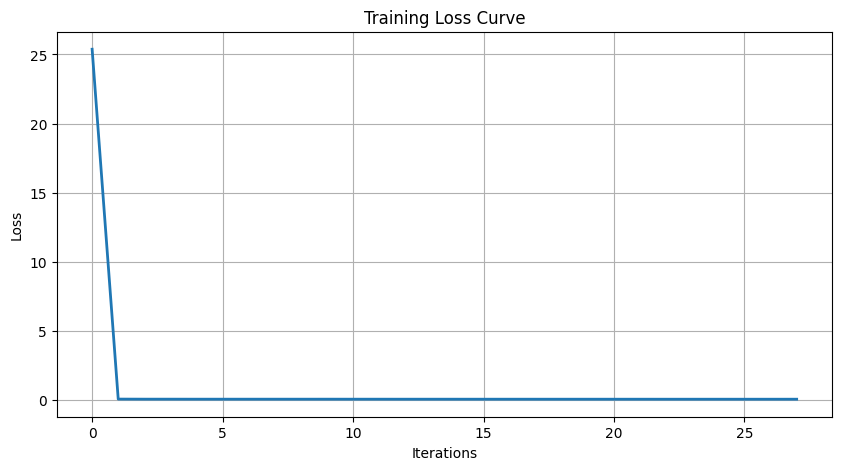

In [27]:
# ==========================================
# Step 21: Training Loss Curve
# ==========================================

plt.figure(figsize=(10,5))

plt.plot(
    mlp_model.loss_curve_,
    linewidth=2
)

plt.title("Training Loss Curve")

plt.xlabel("Iterations")

plt.ylabel("Loss")

plt.grid(True)

plt.show()

In [28]:
# ==========================================
# Step 22: Save Model and Scaler
# ==========================================

joblib.dump(mlp_model, "temperature_mlp_model.pkl")
joblib.dump(scaler, "temperature_scaler.pkl")

print("Model Saved Successfully!")
print("Scaler Saved Successfully!")

Model Saved Successfully!
Scaler Saved Successfully!


In [29]:
# ==========================================
# Step 23: Final Performance Summary
# ==========================================

performance = pd.DataFrame({
    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "MAPE (%)",
        "R² Score",
        "Training Time (s)",
        "Prediction Time (s)"
    ],
    "Value": [
        mae,
        mse,
        rmse,
        mape,
        r2,
        training_time,
        prediction_time
    ]
})

performance

,Metric,Value
0,MAE,0.147172
1,MSE,0.061898
2,RMSE,0.248793
3,MAPE (%),0.503694
4,R² Score,0.995465
5,Training Time (s),91.768060
6,Prediction Time (s),0.519530


In [30]:
# ==========================================
# Display First and Last 30 Rows
# ==========================================

print("========== FIRST 30 ROWS ==========")
display(df[['datetime', 'temp']].head(30))

print("\n========== LAST 30 ROWS ==========")
display(df[['datetime', 'temp']].tail(30))

========== FIRST 30 ROWS ==========


,datetime,temp
0,2017-12-31 21:00:00,17.96
1,2017-12-31 21:15:00,17.82
2,2017-12-31 21:30:00,17.75
3,2017-12-31 21:45:00,17.71
4,2017-12-31 22:00:00,17.60
5,2017-12-31 22:15:00,17.55
6,2017-12-31 22:30:00,17.50
7,2017-12-31 22:45:00,17.40
8,2017-12-31 23:00:00,17.38
9,2017-12-31 23:15:00,17.29



========== LAST 30 ROWS ==========


,datetime,temp
297788,2026-06-29 20:00:00,26.728333
297789,2026-06-29 20:15:00,26.830000
297790,2026-06-29 20:30:00,26.930000
297791,2026-06-29 20:45:00,27.126666
297792,2026-06-29 21:00:00,27.220000
297793,2026-06-29 21:15:00,27.306310
297794,2026-06-29 21:30:00,27.360000
297795,2026-06-29 21:45:00,27.418333
297796,2026-06-29 22:00:00,27.470000
297797,2026-06-29 22:15:00,27.153333


In [31]:
# ==========================================
# Check Recording Interval
# ==========================================

df['datetime'] = pd.to_datetime(df['datetime'])

# Time difference between consecutive records
time_diff = df['datetime'].sort_values().diff()

print("Most Common Time Intervals:")
print(time_diff.value_counts().head(20))

Most Common Time Intervals:
datetime
0 days 00:15:00    297817
Name: count, dtype: int64
